# Fat-Tail Risk & the Hill Estimator — Interactive Walkthrough

This notebook walks through the full analysis step by step.
**Run cells top to bottom.** The synthetic-data checks use a fixed seed (`default_rng(42)`), so they are reproducible.

For production use, run `src/fetch_data.py` first to cache prices.

In [1]:
import sys, pathlib
cur_dir = pathlib.Path().resolve()
src_dir = (cur_dir / "src") if (cur_dir / "src").exists() else (cur_dir.parent / "src")
sys.path.insert(0, str(src_dir))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from hill import (
    log_returns, losses,
    hill_all_k, select_k, hill_ci,
    gaussian_var, weissman_var,
    find_breaches, kupiec_test, alpha_at,
)
from fetch_data import fetch_prices, TICKERS, START, END

matplotlib.rcParams["figure.dpi"] = 110
print("imports OK")

imports OK


## 1  Load prices

In [2]:
RESULTS = (cur_dir / "results") if (cur_dir / "results").exists() else (cur_dir.parent / "results")
CSV = RESULTS / "prices_raw.csv"

if CSV.exists():
    prices = pd.read_csv(CSV, index_col="Date", parse_dates=True)
    print(f"Loaded from cache: {CSV}")
else:
    print("Fetching from yfinance …")
    prices = fetch_prices(list(TICKERS), START, END)
    RESULTS.mkdir(exist_ok=True)
    prices.to_csv(CSV)

prices.tail()

Loaded from cache: /Users/kargor/Downloads/quant-research/01-tail-risk/results/prices_raw.csv


,SPY,QQQ,AAPL,GLD,BTC-USD
Date,,,,,
2026-10-05,774.830017,756.200012,332.890015,379.549988,85786.593750
2026-10-06,779.090027,759.659973,333.630005,382.269989,85557.562500
2026-10-07,777.219971,757.729980,336.670013,375.880005,83275.929688
2026-10-08,773.929993,747.580017,340.420013,378.619995,81676.335938
2026-10-09,778.570007,751.270020,336.640015,384.579987,82546.320312


## 2  Log returns & losses

`loss_t = max(0, −r_t)` — we keep zeros to preserve sample size for VaR.

SPY: 5728 daily returns, 2554 positive loss days


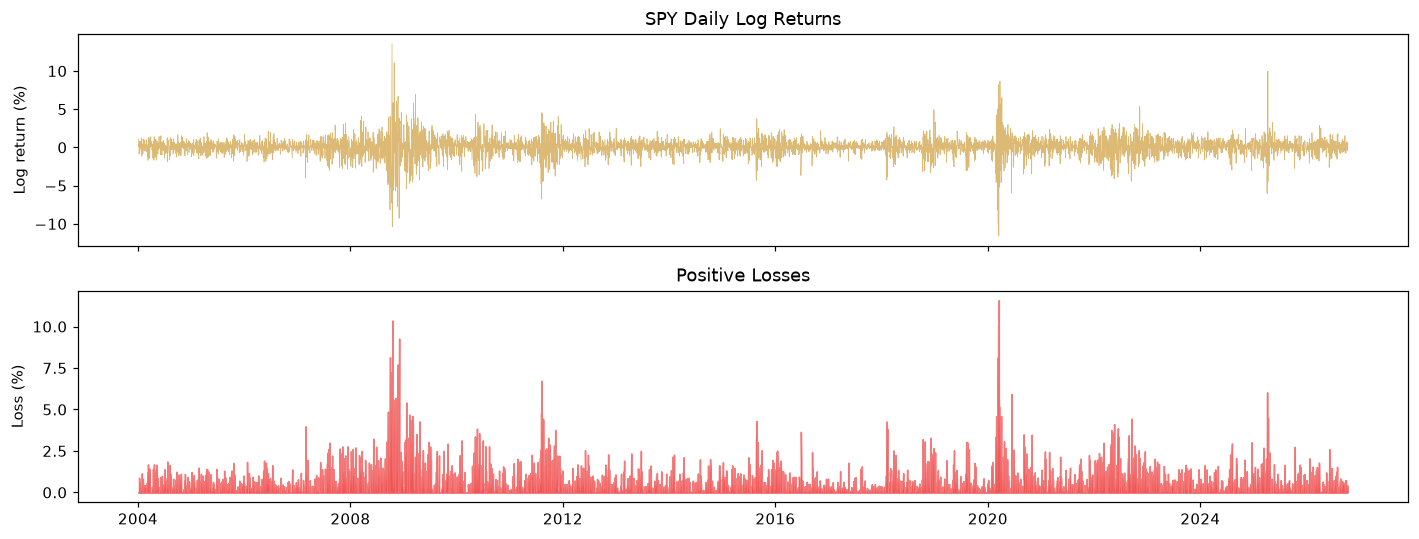

In [3]:
ticker = 'SPY'
ret  = log_returns(prices[ticker].dropna())
loss = losses(ret)

print(f'{ticker}: {len(ret)} daily returns, {(loss > 0).sum()} positive loss days')

fig, axes = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
axes[0].plot(ret.index, ret * 100, linewidth=0.5, color='#d4a853', alpha=0.8)
axes[0].set_ylabel('Log return (%)')
axes[0].set_title(f'{ticker} Daily Log Returns')
axes[1].fill_between(loss.index, loss * 100, alpha=0.7, color='#ef4444')
axes[1].set_ylabel('Loss (%)')
axes[1].set_title('Positive Losses')
fig.tight_layout()

## 3  Gaussian rolling VaR and breach count

In [4]:
from analysis import periods_per_year

ppy  = periods_per_year(ret.index)          # 252 for equities, 365 for BTC
gvar = gaussian_var(ret, confidence=0.99, window=ppy)
bdf  = find_breaches(loss, gvar)

years = gvar.dropna().shape[0] / ppy        # years of VaR forecasts, same as the summary table
print(f'Obs: {len(gvar.dropna())}  |  Breaches: {len(bdf)}  |  '
      f'Per year: {len(bdf)/years:.2f}  |  Expected: {0.01*ppy:.2f}')

# Kupiec test
k = kupiec_test(int(gvar.dropna().shape[0]), len(bdf))
print(f'Kupiec LR={k["lr"]:.2f}  p={k["p_value"]:.4f}  reject_H0={k["reject_h0"]}')

bdf.head(10)

Obs: 5476  |  Breaches: 154  |  Per year: 7.09  |  Expected: 2.52
Kupiec LR=121.82  p=0.0000  reject_H0=True


,loss,var,excess,clustered
date,,,,
2005-10-20,0.017773,0.014706,0.003067,False
2006-01-20,0.018406,0.014588,0.003818,False
2006-05-17,0.019208,0.013458,0.005750,False
2006-05-30,0.017920,0.014049,0.003871,True
2006-06-05,0.014681,0.014364,0.000317,True
2006-07-13,0.016397,0.015401,0.000996,False
2007-02-27,0.039841,0.013452,0.026388,False
2007-03-13,0.019626,0.015031,0.004595,True
2007-06-07,0.018210,0.014082,0.004128,False


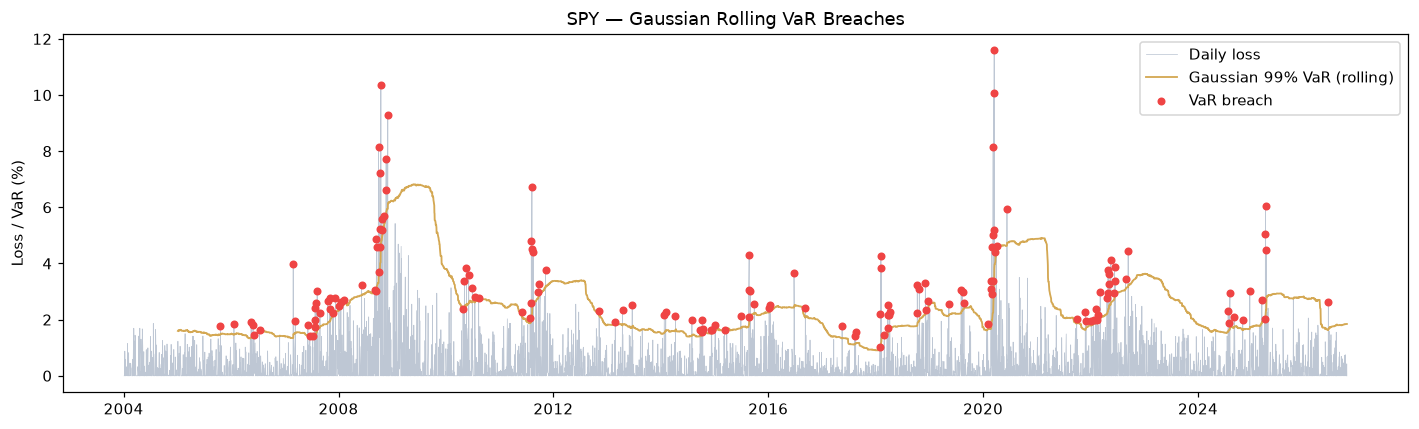

In [5]:
# Plot loss series vs rolling VaR, highlight breaches
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(loss.index, loss * 100, linewidth=0.5, color='#94a3b8', alpha=0.6, label='Daily loss')
ax.plot(gvar.index, gvar * 100, linewidth=1.2, color='#d4a853', label='Gaussian 99% VaR (rolling)')
ax.scatter(bdf.index, bdf['loss'] * 100, color='#ef4444', s=18, zorder=5, label='VaR breach')
ax.set_title(f'{ticker} — Gaussian Rolling VaR Breaches')
ax.set_ylabel('Loss / VaR (%)')
ax.legend()
fig.tight_layout()

## 4  Estimator validation on synthetic data

Before trusting real data, we check the estimator on samples with **known** tail exponents:

* **Pareto(α=3)** is exactly power-law, so Hill should recover 3 at almost any k.
* **Student-t(df=4)** returns are the realistic case: fat-tailed, but only *approximately* Pareto. Hill reads somewhat low here even at a good k, and the old "flattest stretch of the Hill plot" rule returned ≈2.3. That is why `select_k` uses k = √n (see `src/k_selection_study.py`).

In [6]:
rng = np.random.default_rng(42)

def pareto_sample(alpha, n):
    u = rng.uniform(size=n)
    return 1.0 / (1 - u) ** (1 / alpha)

def student_loss(df, n_days):
    # daily losses max(0, -r) for Student-t returns; zeros kept, as with real data
    return np.clip(-rng.standard_t(df, size=n_days), 0, None)

for name, x, true_alpha in [
    ('Pareto(α=3)', pareto_sample(3.0, 10_000), 3.0),
    ('Student-t(df=4)', student_loss(4, 5_700), 4.0),
]:
    ks, alphas = hill_all_k(x)
    best_k, best_alpha = select_k(ks, alphas, n_obs=len(x))
    ci = hill_ci(best_alpha, best_k)
    print(f'{name:25s}  true α={true_alpha}  α̂={best_alpha:.3f} ± {ci:.3f}  at k={best_k}')

Pareto(α=3)                true α=3.0  α̂=2.845 ± 0.284  at k=100
Student-t(df=4)            true α=4.0  α̂=3.790 ± 0.438  at k=75


## 5  Hill plot for all assets

In [7]:
from analysis import run_asset

all_results = {}
for t in prices.columns:
    try:
        all_results[t] = run_asset(t, prices[t].dropna())
    except Exception as e:
        print(f'{t}: {e}')

# Quick summary
rows = []
for r in all_results.values():
    rows.append({
        'Ticker': r['ticker'],
        'α̂': r['alpha_hill'],
        '±': r['alpha_ci'],
        'k*': r['best_k'],
        'Breaches/yr': r['breaches_per_year'],
        'G-VaR 99%': f"{r['gvar_99_full_pct']:.2f}%",
        'W-VaR 99%': f"{r['wvar_99_pct']:.2f}%",
        'G-VaR 99.9%': f"{r['gvar_999_full_pct']:.2f}%",
        'W-VaR 99.9%': f"{r['wvar_999_pct']:.2f}%",
    })
pd.DataFrame(rows)

,Ticker,α̂,±,k*,Breaches/yr,G-VaR 99%,W-VaR 99%,G-VaR 99.9%,W-VaR 99.9%
0,SPY,2.689,0.308,76,7.09,2.69%,3.40%,3.58%,8.00%
1,QQQ,3.555,0.408,76,6.53,3.08%,3.80%,4.12%,7.26%
2,AAPL,3.523,0.404,76,4.97,4.62%,5.43%,6.18%,10.44%
3,GLD,3.443,0.400,74,5.76,2.64%,3.28%,3.52%,6.41%
4,BTC-USD,3.183,0.392,66,6.96,7.98%,10.12%,10.63%,20.86%


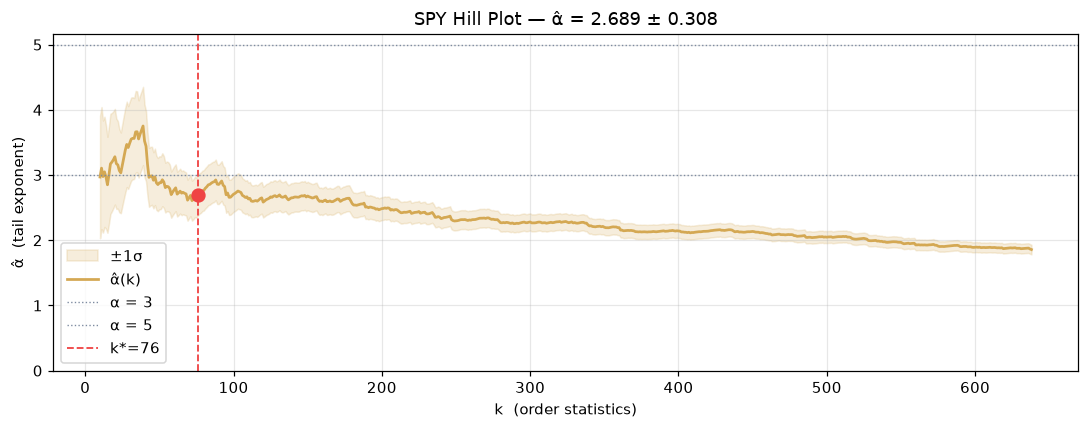

In [8]:
# Interactive Hill plot for one asset — change `ticker` to explore
ticker = 'SPY'
r = all_results[ticker]

fig, ax = plt.subplots(figsize=(10, 4))
ks, alphas = r['ks'], r['alphas']
ci_band = np.array([hill_ci(a, k) for a, k in zip(alphas, ks)])

ax.fill_between(ks, alphas - ci_band, alphas + ci_band, alpha=0.2, color='#d4a853', label='±1σ')
ax.plot(ks, alphas, color='#d4a853', linewidth=1.8, label='α̂(k)')
ax.axhline(3, color='#7d8ba0', linestyle=':', linewidth=0.9, label='α = 3')
ax.axhline(5, color='#7d8ba0', linestyle=':', linewidth=0.9, label='α = 5')
ax.axvline(r['best_k'], color='#ef4444', linestyle='--', linewidth=1.2, label=f"k*={r['best_k']}")
ax.scatter([r['best_k']], [r['alpha_hill']], color='#ef4444', s=70, zorder=5)
ax.set(title=f'{ticker} Hill Plot — α̂ = {r["alpha_hill"]:.3f} ± {r["alpha_ci"]:.3f}',
       xlabel='k  (order statistics)', ylabel='α̂  (tail exponent)')
ax.set_ylim(0)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

## 6  k sensitivity

α̂ at k* ± 20 %. Small moves mean the estimate is not an artefact of the exact k; on real data the Hill plot keeps drifting down as k grows, so expect some movement.

In [9]:
for ticker, r in all_results.items():
    ks, alphas, k_star = r['ks'], r['alphas'], r['best_k']
    for delta_pct in [-20, 0, +20]:
        k_try = round(k_star * (1 + delta_pct / 100))
        print(f'{ticker:8s}  k={k_try:4d} ({delta_pct:+3d}%)  α̂={alpha_at(ks, alphas, k_try):.3f}')
    print()

SPY       k=  61 (-20%)  α̂=2.804
SPY       k=  76 ( +0%)  α̂=2.689
SPY       k=  91 (+20%)  α̂=2.881

QQQ       k=  61 (-20%)  α̂=3.750
QQQ       k=  76 ( +0%)  α̂=3.555
QQQ       k=  91 (+20%)  α̂=3.330

AAPL      k=  61 (-20%)  α̂=3.574
AAPL      k=  76 ( +0%)  α̂=3.523
AAPL      k=  91 (+20%)  α̂=3.549

GLD       k=  59 (-20%)  α̂=3.260
GLD       k=  74 ( +0%)  α̂=3.443
GLD       k=  89 (+20%)  α̂=3.327

BTC-USD   k=  53 (-20%)  α̂=3.961
BTC-USD   k=  66 ( +0%)  α̂=3.183
BTC-USD   k=  79 (+20%)  α̂=2.872



## 7  Loss tail vs gain tail (bonus)

A difference only means something if it is larger than the estimates' uncertainty, so each comparison reports the gap in standard errors (each α̂ has s.e. ≈ α̂/√k).

In [10]:
def gains(returns):
    return returns.clip(lower=0)

for ticker, r in all_results.items():
    ret = r['ret_series']
    n = len(ret)
    k_l, al = select_k(*hill_all_k(losses(ret)), n_obs=n)
    k_g, ag = select_k(*hill_all_k(gains(ret)), n_obs=n)
    se = np.hypot(hill_ci(al, k_l), hill_ci(ag, k_g))
    z = (ag - al) / se
    verdict = ('heavier losses' if z > 0 else 'heavier gains') if abs(z) > 2 else 'no clear difference'
    print(f'{ticker:8s}  loss α̂={al:.2f}  gain α̂={ag:.2f}  gap={z:+.1f} s.e.  → {verdict}')

SPY       loss α̂=2.69  gain α̂=2.65  gap=-0.1 s.e.  → no clear difference
QQQ       loss α̂=3.56  gain α̂=3.35  gap=-0.4 s.e.  → no clear difference
AAPL      loss α̂=3.52  gain α̂=3.23  gap=-0.5 s.e.  → no clear difference
GLD       loss α̂=3.44  gain α̂=4.57  gap=+1.7 s.e.  → no clear difference
BTC-USD   loss α̂=3.18  gain α̂=4.70  gap=+2.2 s.e.  → heavier losses


## 8  Save all figures

In [11]:
from plots import plot_hill, plot_breach_heatmap, plot_var_compare

plot_hill(all_results, RESULTS / "hill_plots.png")
plot_breach_heatmap(all_results, RESULTS / "breach_heatmap.png")
plot_var_compare(all_results, RESULTS / "var_compare.png")
print("Figures saved.")

Saved → /Users/kargor/Downloads/quant-research/01-tail-risk/results/hill_plots.png


Saved → /Users/kargor/Downloads/quant-research/01-tail-risk/results/breach_heatmap.png
Saved → /Users/kargor/Downloads/quant-research/01-tail-risk/results/var_compare.png
Figures saved.
